# Experiment 3
## Optimal signature truncation order.
### Synthetic data

In [1]:
import sys, os
sys.path.append(os.path.abspath(".."))

from src.imports import *
from src.simulation import consumption_simulate
from src.ridge_signatures import ridge_signatures
from src.baselines import run_baselines_synthetic
from src.utils import setup_latex_plotting

All imports are fine


### Load data

In [2]:
base_dir = Path.cwd().parent
file_path = base_dir / "data" / "data.csv"

df = pd.read_csv(file_path, decimal=".")
df["DateTime"] = pd.to_datetime(df["DateTime"])
temp = np.array(df["Temperature"])
consumption = np.array(df["Consumption"])

### Fit RidgeSig models with different truncation orders to synthetic data

The code allows for different smoothing parameters that simulate different synthetic data sets. On each, ridge regression models on sliding-window signatures with varying truncation orders and window sizes are fitted.


In [ ]:
smooth_params = [0.005]
sd = 500

delay_days = 2  
delay = delay_days*48
n_windows = 31
windows_days = np.array(range(delay_days, n_windows + delay_days))
windows = [48 * i for i in windows_days]
lambdas = np.logspace(-3, 3, 50)
n_train = (df["DateTime"] < "2014-01-01 00:00:00").sum()
n_valid = ((df["DateTime"] >= "2014-01-01 00:00:00") & 
           (df["DateTime"] <  "2015-01-01 00:00:00")).sum()
trunc_orders = [2,3,4,5,6,7]
lambdas = np.logspace(-1, 3, 20)
metric="rmse"

lams_efm = np.linspace(10,20,5) #confiugure lambdas for EFM
n_lams = lams_efm.shape[0]

consumption_sim = np.empty((len(smooth_params), len(consumption)))
error_trunc_efm   = np.empty((len(smooth_params), len(trunc_orders), n_lams))

for i, alpha in enumerate(smooth_params):
    # Simulate consumption for different smoothing parameters
    consumption_sim[i, :] = consumption_simulate(
        df, sd, smooth_param=alpha, fixed_seed=141
    )

    for j, d in enumerate(trunc_orders):
        for k, lam in enumerate(lams_efm):
            print(f'processing for lambda efm : {lam}')
            result_efm = ridge_signatures(
                covariates=temp,
                target=consumption_sim[i, :],
                window=0, # not needed for EFM
                delay=delay,
                n_train=n_train,
                n_valid=n_valid,
                trunc_order=d,
                penalties=lambdas,
                tune_penalty=True,
                metric=metric,
                signature_type='efm',
                lam = np.array([lam]), # EFM lambda is taken as constant
                max_window=max(windows) # window taken for the convergence of EFM 
            )
            error_trunc_efm[i, j, k] = result_efm["error_test"]


processing for lambda efm : 10.0
t_grid: (1, 70128)
Path shape: (70128, 2)
y size: 68592
Time taken to compute EFM signatures: 0.18 seconds
EFM signatures shape: (68592, 15)
X_train: (33552, 15)
X_val: (17520, 15)
X_test: (17520, 15)
-----------------------------------------
total train+val+test: 68592
total data: 68592
processing for lambda efm : 12.5
t_grid: (1, 70128)
Path shape: (70128, 2)
y size: 68592
Time taken to compute EFM signatures: 0.18 seconds
EFM signatures shape: (68592, 15)
X_train: (33552, 15)
X_val: (17520, 15)
X_test: (17520, 15)
-----------------------------------------
total train+val+test: 68592
total data: 68592
processing for lambda efm : 15.0
t_grid: (1, 70128)
Path shape: (70128, 2)
y size: 68592
Time taken to compute EFM signatures: 0.18 seconds
EFM signatures shape: (68592, 15)
X_train: (33552, 15)
X_val: (17520, 15)
X_test: (17520, 15)
-----------------------------------------
total train+val+test: 68592
total data: 68592
processing for lambda efm : 17.5
t

### Plot
For the chosen smoothing parameter, the plot of error metric against different window sizes is obtained, with different colored curves corresponding to different depths.

findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: 

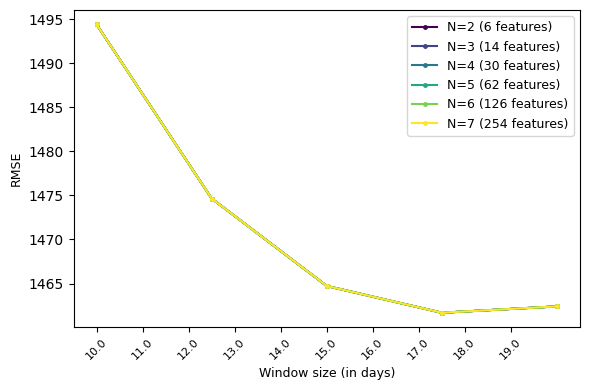

In [9]:
setup_latex_plotting()

n_trunc = len(trunc_orders)
cmap = mpl.colormaps["viridis"].resampled(n_trunc)  
colors = [cmap(i) for i in range(n_trunc)]

x = lams_efm


xticks = np.arange(lams_efm[0], lams_efm[-1])
xticklabels = xticks


fig, ax = plt.subplots(figsize=(6, 4))

for j, d in enumerate(trunc_orders):
    n_features = iisignature.siglength(2, d)
    
    ax.plot(
        x ,
        error_trunc_efm[0, j],
        marker='.',
        markersize=5,
        color=colors[j],
        label=f"N={d} ({n_features} features)"
    )

ax.set_xlabel("Window size (in days)",fontsize=9)
ax.set_ylabel(metric.upper(),fontsize=9)
ax.set_xticks(xticks)
ax.set_xticklabels(xticklabels)
ax.tick_params(axis='x', labelrotation=45,labelsize=8)
ax.legend(fontsize=9)

plt.tight_layout()
plt.show()